# EXPLORATORY DATA ANALYSIS WITH CLEAN DATASET

## Dataset overview

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [8]:
df = pd.read_csv('D:/Project 4 - Global Mobile Reviews/Mobile Recommendation/cleaned_data.csv',parse_dates = ['Review_date'])

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47432 entries, 0 to 47431
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Customer_age          47432 non-null  int64         
 1   Brand                 47432 non-null  str           
 2   Model                 47432 non-null  str           
 3   Source                47432 non-null  str           
 4   Country               47432 non-null  str           
 5   Currency              47432 non-null  str           
 6   Exchange_rate_to_usd  47432 non-null  float64       
 7   Price_local           47432 non-null  float64       
 8   Price_usd             47432 non-null  float64       
 9   Verified_purchase     47432 non-null  int64         
 10  Review_date           47432 non-null  datetime64[us]
 11  Rating                47432 non-null  int64         
 12  Battery_life_rating   47432 non-null  int64         
 13  Camera_rating         47432

In [10]:
print(f'''Dataset dimensions - {df.shape}''')

Dataset dimensions - (47432, 18)


In [11]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Customer_age,47432.0,30.066432,18.0,23.0,29.0,36.0,65.0,8.941558
Exchange_rate_to_usd,47432.0,12.086481,0.78,1.0,1.53,5.7,83.0,26.585522
Price_local,47432.0,8318.574242,141.09,594.2575,1060.84,2936.1475,124397.08,20427.329043
Price_usd,47432.0,689.780473,180.07,450.71,637.04,900.6425,1499.82,310.203864
Verified_purchase,47432.0,0.801653,0.0,1.0,1.0,1.0,1.0,0.398759
Review_date,47432,2024-04-20 02:10:39.973014,2022-10-22 00:00:00,2023-07-19 00:00:00,2024-04-20 00:00:00,2025-01-19 00:00:00,2025-10-21 00:00:00,NaN
Rating,47432.0,3.123777,1.0,2.0,3.0,4.0,5.0,1.249269
Battery_life_rating,47432.0,2.71905,1.0,1.0,3.0,4.0,5.0,1.348571
Camera_rating,47432.0,2.719683,1.0,1.0,3.0,4.0,5.0,1.345635
Performance_rating,47432.0,2.720294,1.0,1.0,3.0,4.0,5.0,1.348806


In [12]:
df.describe(include  = 'object').T

C:\Users\RD\AppData\Local\Temp\ipykernel_4168\2028766291.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include  = 'object').T


,count,unique,top,freq
Brand,47432,7,Xiaomi,6851
Model,47432,22,Realme Narzo 70,3417
Source,47432,6,eBay,9082
Country,47432,8,USA,6108
Currency,47432,8,USD,6108


What the dataset looks like
- The dataset has **47,432 reviews** and **18 columns**, and there are no missing values left.
- It covers **7 brands**, **22 phone models** and **8 countries**.
- Reviews were posted on **5 shopping sites** (eBay, AliExpress, Amazon, Flipkart, BestBuy). A few reviews have the source "Unknown" because the site name was missing.
- Prices range from about **$180 to $1,500**, and ratings go from 1 to 5.

## Outlier analysis

In [13]:
def iqr_report(cols):
    rows = []
    for c in cols:
        q1, q3 = df[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = ((df[c] < lo) | (df[c] > hi)).sum()
        rows.append([c, df[c].min(), df[c].max(), round(lo, 2), round(hi, 2), n, round(n / len(df) * 100, 2)])
    return pd.DataFrame(rows, columns=["Column", "Min", "Max", "Lower bound", "Upper bound", "IQR-flagged", "% flagged"])

iqr_report(['Customer_age','Exchange_rate_to_usd','Price_local','Price_usd','Rating','Battery_life_rating',
            'Camera_rating','Performance_rating','Design_rating','Display_rating','Helpful_votes'] )

,Column,Min,Max,Lower bound,Upper bound,IQR-flagged,% flagged
0,Customer_age,18.00,65.00,3.50,55.50,180,0.38
1,Exchange_rate_to_usd,0.78,83.00,-6.05,12.75,5826,12.28
2,Price_local,141.09,124397.08,-2918.58,6448.98,6503,13.71
3,Price_usd,180.07,1499.82,-224.19,1575.54,0,0.00
4,Rating,1.00,5.00,-1.00,7.00,0,0.00
5,Battery_life_rating,1.00,5.00,-3.50,8.50,0,0.00
6,Camera_rating,1.00,5.00,-3.50,8.50,0,0.00
7,Performance_rating,1.00,5.00,-3.50,8.50,0,0.00
8,Design_rating,1.00,5.00,-3.50,8.50,0,0.00
9,Display_rating,1.00,5.00,-3.50,8.50,0,0.00


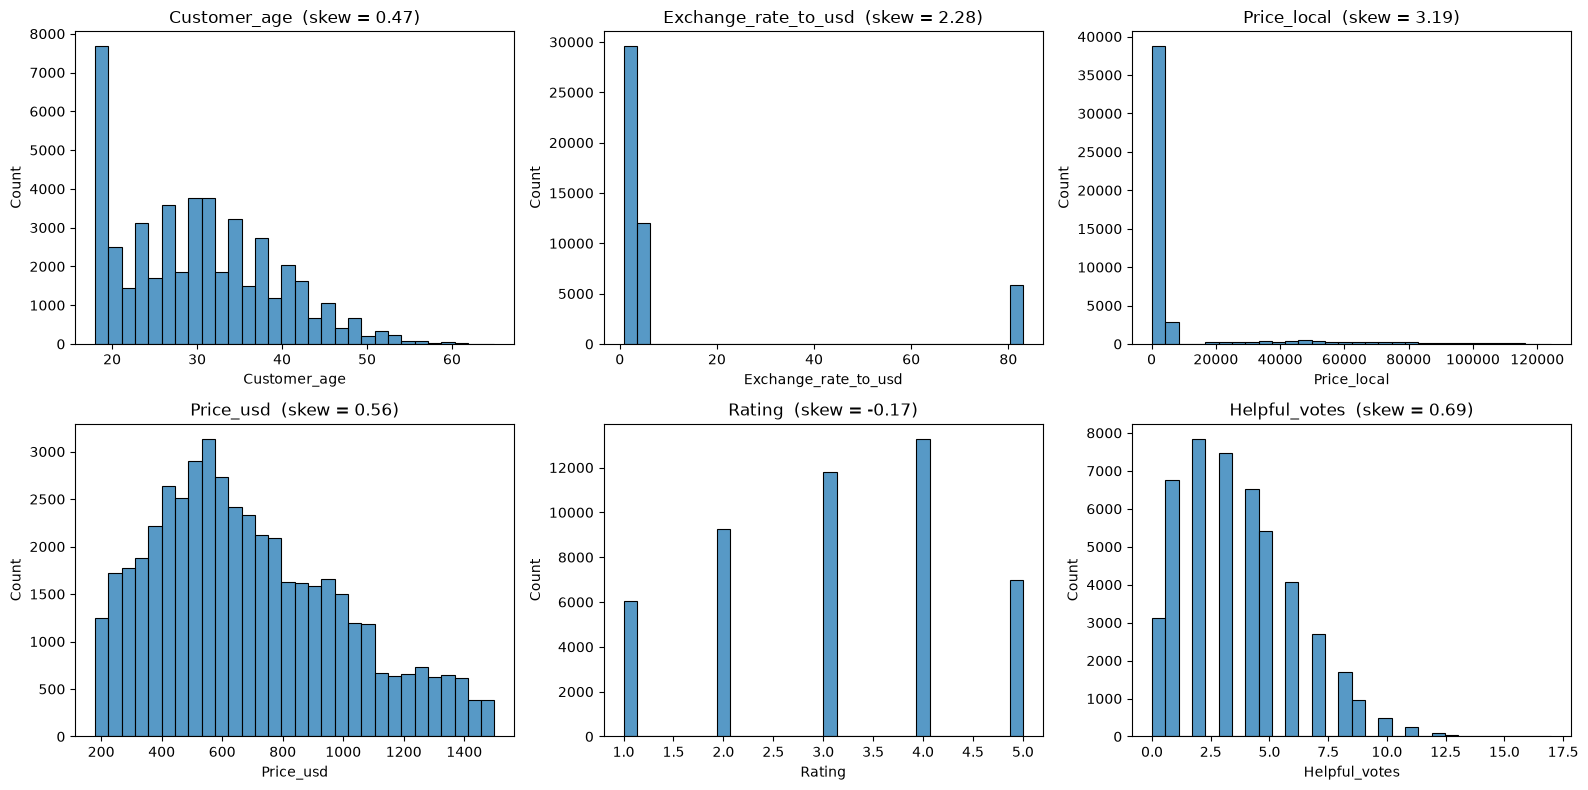

In [14]:
cols = ['Customer_age','Exchange_rate_to_usd','Price_local','Price_usd','Rating','Helpful_votes']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for ax, c in zip(axes, cols):
    sns.histplot(df[c], bins=30, ax=ax)
    ax.set_title(f"{c}  (skew = {df[c].skew():.2f})")

plt.tight_layout()
plt.show()

- **Price (USD):** nothing unusual. Prices run from about $180 to $1,500. Each brand has its own price range (Realme is cheapest, Apple is the most expensive), so a high price just means a premium phone, not a mistake.
- **Ratings:** all values are between 1 and 5, so nothing is impossible.
- **Customer age:** ages run from 18 to 65, which is realistic. Only a small number of older customers (under 0.4%) look unusual, and they are real people.
- **Helpful votes:** some reviews got many more votes than others. That is normal, because a few reviews always get more attention.
- **Price in local currency and exchange rate:** these columns look like they have outliers, but only because they mix 8 currencies. Numbers in Indian rupees are naturally much bigger than numbers in pounds. This is not a data problem, and USD price is used for the analysis.

**Conclusion:** none of the values are mistakes, so no rows were removed.

## Skewness

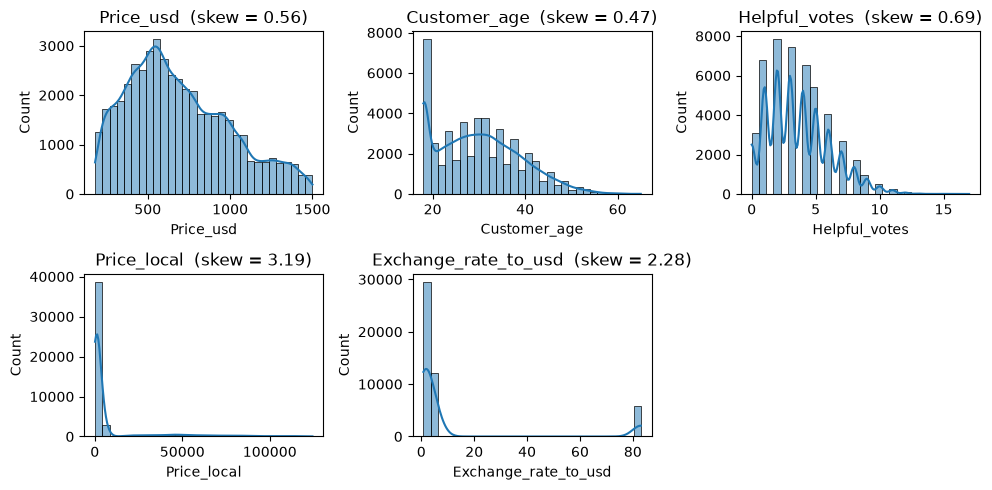

In [15]:
skew_cols = ["Price_usd", "Customer_age", "Helpful_votes", "Price_local", "Exchange_rate_to_usd"]

fig, axes = plt.subplots(2, 3, figsize=(10, 5))
axes = axes.flatten()
for ax, c in zip(axes, skew_cols):
    sns.histplot(df[c], kde=True, bins=30, ax=ax)
    ax.set_title(f"{c}  (skew = {df[c].skew():.2f})")
axes[-1].axis("off")
plt.tight_layout(); plt.show()

In [16]:
# Price_local looks highly skewed only because 8 currencies are mixed - check per currency
df.groupby("Currency")["Price_local"].skew().round(2)

Currency
AED    0.56
AUD    0.54
BRL    0.56
CAD    0.54
EUR    0.54
GBP    0.57
INR    0.57
USD    0.61
Name: Price_local, dtype: float64

- **Price (USD), customer age and helpful votes** have small skews (between 0.47 and 0.69). Most customers are younger and most reviews get a few votes, with a small number reaching higher values. This is mild, so no modifications are made.
- **Price in local currency and exchange rate** look very lopsided, but only because 8 currencies are mixed together. Checked separately, each currency's skew is about 0.54 to 0.61, close to the USD price.

**Conclusion:** no data changes are needed, and the USD price is used in the analysis.

# Statistical summary and comparisons

In [17]:
rating_cols = ["Rating", "Battery_life_rating", "Camera_rating","Performance_rating", "Design_rating", "Display_rating"]
num_cols = ["Price_usd"] + rating_cols

# -------------- Average values for each brand --------------
df.groupby("Brand")[num_cols].mean().round(2).sort_values("Price_usd")

,Price_usd,Rating,Battery_life_rating,Camera_rating,Performance_rating,Design_rating,Display_rating
Brand,,,,,,,
Realme,393.23,3.14,2.73,2.72,2.75,2.72,2.75
Xiaomi,449.75,3.12,2.71,2.72,2.72,2.71,2.71
Motorola,506.61,3.11,2.70,2.69,2.71,2.70,2.72
OnePlus,673.11,3.13,2.72,2.73,2.73,2.70,2.73
Google,804.79,3.13,2.73,2.72,2.71,2.72,2.74
Samsung,900.25,3.11,2.72,2.71,2.70,2.71,2.70
Apple,1103.71,3.13,2.73,2.74,2.72,2.73,2.72


In [18]:
df.groupby("Country").agg(Total_Reviews=("Rating", "size"), Avg_price_usd=("Price_usd", "mean"), Avg_rating=("Rating", "mean")).round(2)

,Total_Reviews,Avg_price_usd,Avg_rating
Country,,,
Australia,5913,689.62,3.14
Brazil,6085,693.71,3.12
Canada,5843,689.61,3.12
Germany,5850,694.23,3.11
India,5826,687.73,3.12
UAE,5943,689.28,3.14
UK,5864,687.47,3.13
USA,6108,686.59,3.12


- **Price differs a lot between brands:** Realme is the cheapest (about $393) and Apple is the most expensive (about $1,104). Samsung ($900) and Google ($805) are the next most expensive after Apple.
- **Ratings barely change between brands.** Every brand averages around **3.1 out of 5**, no matter how expensive its phones are. The overall rating and the five part-ratings (battery, camera, performance, design, display) look almost the same everywhere.
- **Countries are very similar too.** The average price is about $690 in every country, and the average rating is about 3.1.

**Takeaway:** the brand or the country does not change how customers rate the phones. The main difference between brands is the price.

# Distribution of reviews across countries and mobile brands

In [19]:
# -------------- No.of reviews for each brand --------------
df['Brand'].value_counts()

Brand
Xiaomi      6851
Google      6840
OnePlus     6791
Realme      6778
Apple       6757
Samsung     6710
Motorola    6705
Name: count, dtype: int64

In [20]:
# -------------- No.of reviews for each country --------------
df['Country'].value_counts()

Country
USA          6108
Brazil       6085
UAE          5943
Australia    5913
UK           5864
Germany      5850
Canada       5843
India        5826
Name: count, dtype: int64

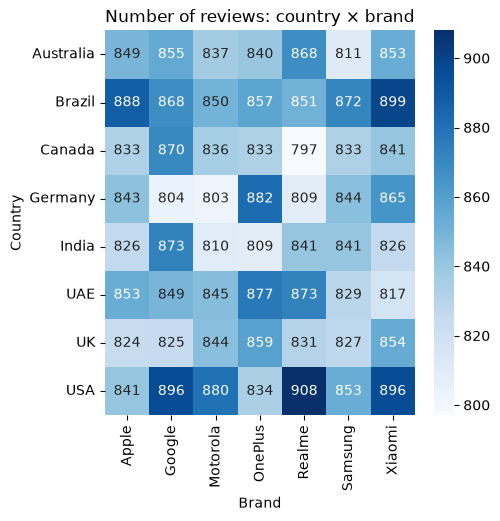

In [21]:
plt.figure(figsize=(5, 5))
sns.heatmap(pd.crosstab(df["Country"], df["Brand"]), annot=True, fmt="d", cmap="Blues")
plt.title("Number of reviews: country × brand"); plt.show()

- Each brand has roughly the same number of reviews (about 6,700 to 6,850).
- Each country has roughly the same number of reviews (about 5,800 to 6,100).
- In the country × brand heatmap, every box has roughly 800 to 900 reviews.

**Takeaway:** no brand or country dominates, so the data is fair to every group and none of the results are pulled towards one brand.

# Top-rated and low-rated products

In [22]:
model_stats = (df.groupby(["Brand", "Model"])
                 .agg(Avg_rating=("Rating", "mean"),
                      Avg_price=("Price_usd", "mean"),
                      Reviews=("Rating", "count"),
                      percentage_of_ratings_above_4 =("Rating", lambda s: (s >= 4).mean() * 100),
                      percentage_of_ratings_below_2=("Rating", lambda s: (s <= 2).mean() * 100))
                 .round(2).sort_values("Avg_rating").reset_index())

print("Highest rated models"); display(model_stats.tail(5).iloc[::-1])
print("Lowest rated models"); display(model_stats.head(5))

Highest rated models


,Brand,Model,Avg_rating,Avg_price,Reviews,percentage_of_ratings_above_4,percentage_of_ratings_below_2
21,Apple,iPhone 14,3.19,1099.19,1687,44.40,30.17
20,Apple,iPhone 13,3.16,1107.73,1677,44.13,31.72
19,Samsung,Galaxy Note 20,3.15,903.69,1707,41.83,30.40
18,Realme,Realme 12 Pro,3.15,393.95,3361,43.77,31.30
17,OnePlus,OnePlus Nord 3,3.14,675.14,2268,44.40,31.79


Lowest rated models


,Brand,Model,Avg_rating,Avg_price,Reviews,percentage_of_ratings_above_4,percentage_of_ratings_below_2
0,Samsung,Galaxy S24,3.07,897.36,1668,39.81,33.51
1,Apple,iPhone 15 Pro,3.09,1105.32,1688,42.89,34.72
2,Samsung,Galaxy A55,3.09,901.65,1710,42.11,33.74
3,Motorola,Edge 50,3.09,508.04,2178,41.92,34.25
4,Xiaomi,Mi 13 Pro,3.10,448.67,2324,42.25,33.35


In [23]:
brand_rating = df.groupby("Brand")["Rating"].agg(["mean", "count"]).round(3).sort_values("mean")
brand_rating

,mean,count
Brand,,
Motorola,3.109,6705
Samsung,3.114,6710
Xiaomi,3.115,6851
Google,3.126,6840
OnePlus,3.133,6791
Apple,3.133,6757
Realme,3.136,6778


In [24]:
print(f"Rated 4 or 5: {(df['Rating'] >= 4).mean():.1%}")
print(f"Rated 1 or 2: {(df['Rating'] <= 2).mean():.1%}")
print(f"Age 35 or younger: {(df['Customer_age'] <= 35).mean():.1%}")

Rated 4 or 5: 42.7%
Rated 1 or 2: 32.3%
Age 35 or younger: 72.8%


- **Highest rated:** iPhone 14 (3.19), iPhone 13 (3.16) and Galaxy Note 20 (3.15).
- **Lowest rated:** Galaxy S24 (3.07), iPhone 15 Pro (3.09) and Galaxy A55 (3.09).
- **The gap is tiny.** The best phone scores only about 0.12 points higher than the worst one, on a scale of 1 to 5. In practice, all phones are rated about the same.
- Apple and Samsung appear in both the top and the bottom lists, so a brand name does not guarantee good or bad ratings.
- Across all reviews, about 43% give 4 or 5 rating and about 32% give 1 or 2 rating.

**Takeaway:** customers are mixed about every phone. No model is clearly loved or disliked.

# Price Vs Ratings

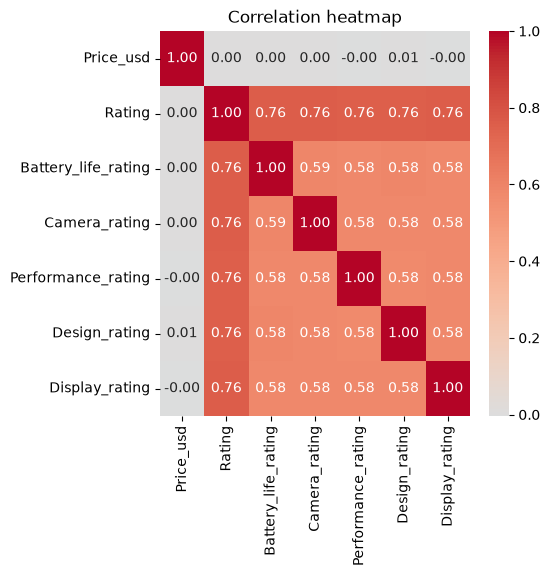

In [25]:
plt.figure(figsize=(5, 5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.show()

In [26]:
# Price tier vs satisfaction
df["Price_tier"] = pd.qcut(df["Price_usd"], 4, labels=["Q1 (cheapest)", "Q2", "Q3", "Q4 (priciest)"])
df.groupby("Price_tier", observed=True)[rating_cols].mean().round(3)

,Rating,Battery_life_rating,Camera_rating,Performance_rating,Design_rating,Display_rating
Price_tier,,,,,,
Q1 (cheapest),3.119,2.706,2.719,2.723,2.706,2.718
Q2,3.122,2.720,2.711,2.729,2.703,2.722
Q3,3.119,2.721,2.723,2.710,2.717,2.726
Q4 (priciest),3.135,2.729,2.726,2.719,2.730,2.722


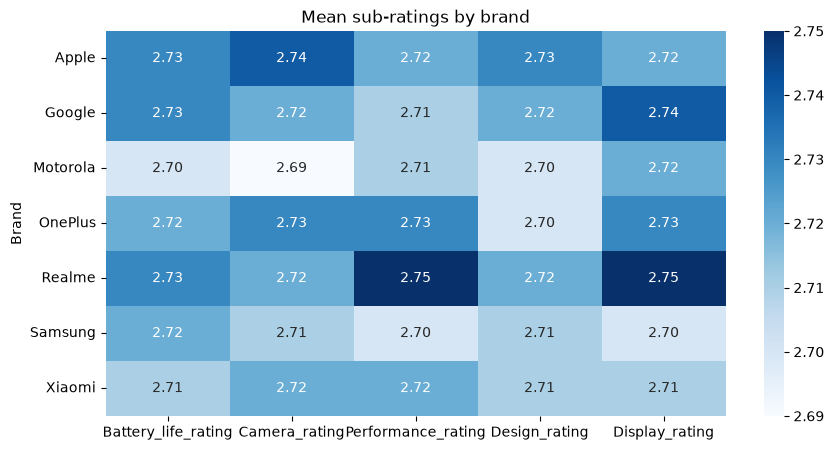

In [27]:
# Sub-ratings by brand
sub = ["Battery_life_rating", "Camera_rating", "Performance_rating", "Design_rating", "Display_rating"]
plt.figure(figsize=(10, 5))
sns.heatmap(df.groupby("Brand")[sub].mean().round(2), annot=True, fmt=".2f", cmap="Blues")
plt.title("Mean sub-ratings by brand"); plt.show()

- **Price and rating:** the number is about **0**. Expensive phones are not rated higher than cheap ones.
- **Price groups:** Reviews are split into four groups from cheapest to most expensive. The average rating is nearly the same in all of them (about 3.12 to 3.14).
- **Overall rating and the part-ratings:** each part (battery, camera, performance, design, display) has a link of about **0.76** with the overall rating. When someone is happy overall, they tend to rate every part higher too.
- The part-ratings are also linked with each other (about 0.58), so they move together.
- On average the part-ratings (about 2.7) are lower than the overall rating (about 3.1).

**Takeaway:** paying more does not buy happier customers in this data. Price decides which group a phone belongs to (budget, mid-range or premium), but it does not decide how good the reviews are.

# Patterns and Trends

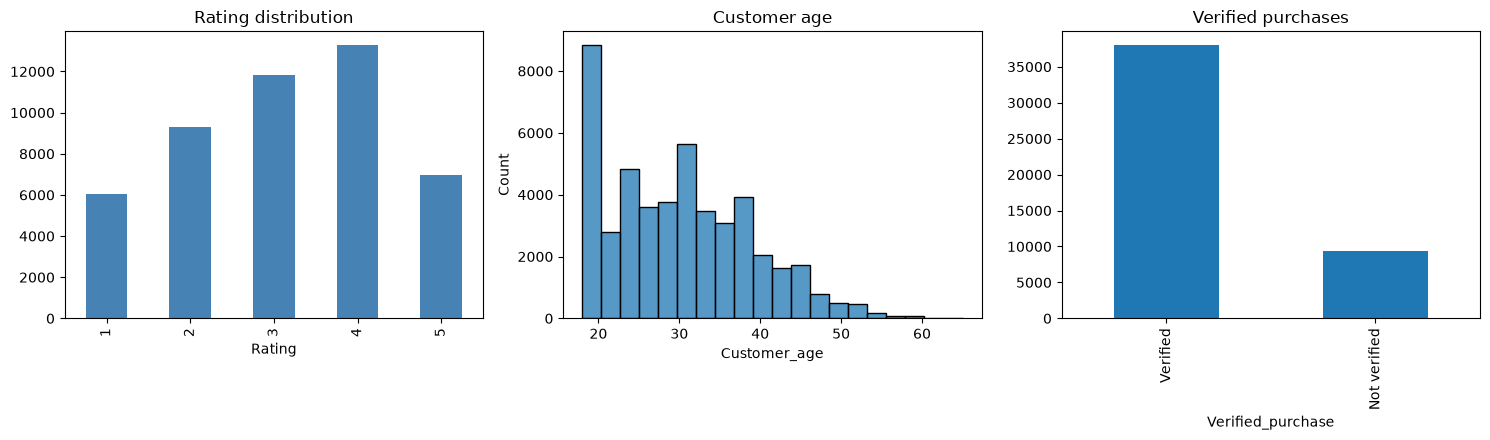

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
df["Rating"].value_counts().sort_index().plot(kind="bar", ax=ax[0], color="steelblue", title="Rating distribution")
sns.histplot(df["Customer_age"], bins=20, ax=ax[1]); ax[1].set_title("Customer age")
df["Verified_purchase"].map({1: "Verified", 0: "Not verified"}).value_counts().plot(kind="bar", ax=ax[2], title="Verified purchases")
plt.tight_layout(); plt.show()

In [29]:
print("Mean rating by verified purchase:")
print(df.groupby("Verified_purchase")["Rating"].mean().round(3))

df["Age_group"] = pd.cut(df["Customer_age"], [17, 25, 35, 45, 55, 65],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-65"])
print("\nMean rating by age group:")
print(df.groupby("Age_group", observed=True)["Rating"].mean().round(3))

Mean rating by verified purchase:
Verified_purchase
0    3.129
1    3.123
Name: Rating, dtype: float64

Mean rating by age group:
Age_group
18-25    3.111
26-35    3.126
36-45    3.126
46-55    3.171
56-65    3.194
Name: Rating, dtype: float64


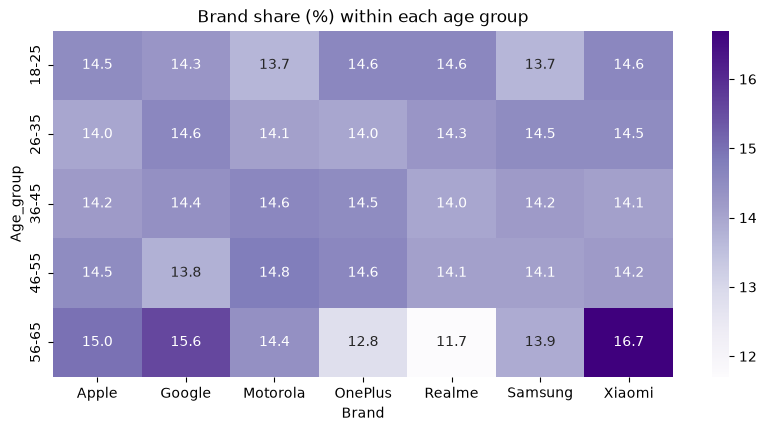

In [30]:
# Brand preference by age group
pref = pd.crosstab(df["Age_group"], df["Brand"], normalize="index") * 100
plt.figure(figsize=(10, 4.5))
sns.heatmap(pref.round(1), annot=True, fmt=".1f", cmap="Purples")
plt.title("Brand share (%) within each age group"); plt.show()

In [31]:
print(f"Rated 4 or 5: {(df['Rating'] >= 4).mean():.1%}")
print(f"Rated 1 or 2: {(df['Rating'] <= 2).mean():.1%}")
print(f"Age 35 or younger: {(df['Customer_age'] <= 35).mean():.1%}")

Rated 4 or 5: 42.7%
Rated 1 or 2: 32.3%
Age 35 or younger: 72.8%


- **Ratings:** 4 stars is the most common score (28%), then 3 stars (25%). 5 stars is given 15% of the time and 1 star about 13%.
- **Age:** most reviewers are young. About 73% are 35 or younger, and the typical (median) age is 29.
- **Age and rating:** the average rating is almost the same in every age group (between 3.11 and 3.19). The small rise for older customers is too small to count as a real pattern, so age does not change how people rate phones.
- **Verified purchases:** about 80% of reviews come from verified buyers. Verified and non-verified reviews give the same average rating (3.12 vs 3.13), so I can trust both kinds.
- **Brand choice by age:** in every age group each brand has about the same share (around 14%). Only the 56-65 group looks a bit different, but it has just 180 reviews, so that is likely chance. Age does not point to a favourite brand.

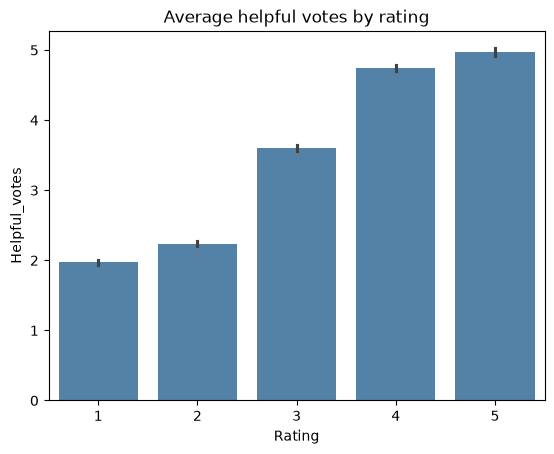

Correlation (Helpful_votes, Rating): 0.46


In [32]:
# Helpful votes vs rating
sns.barplot(data=df, x="Rating", y="Helpful_votes", color="steelblue")
plt.title("Average helpful votes by rating"); plt.show()
print("Correlation (Helpful_votes, Rating):", round(df["Helpful_votes"].corr(df["Rating"]), 2))

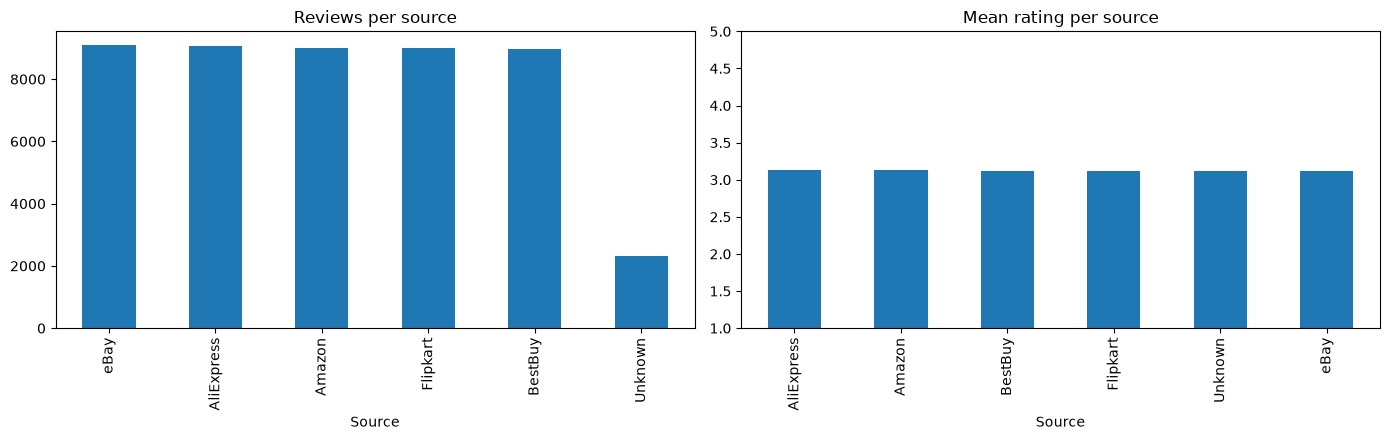

In [33]:
# Review source
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df["Source"].value_counts().plot(kind="bar", ax=ax[0], title="Reviews per source")
df.groupby("Source")["Rating"].mean().plot(kind="bar", ax=ax[1], title="Mean rating per source", ylim=(1, 5))
plt.tight_layout(); plt.show()

Date range: 2022-10-22 to 2025-10-21


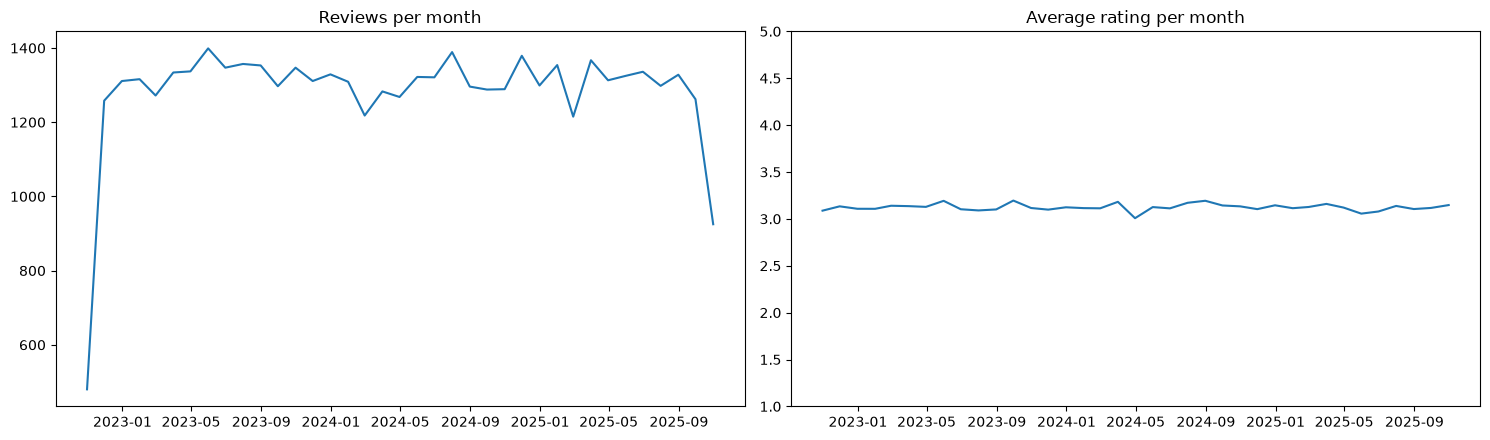

In [34]:
# Time trend
monthly = df.set_index("Review_date").resample("ME").agg(Reviews=("Rating", "size"), Avg_rating=("Rating", "mean"), Avg_price=("Price_usd", "mean")).reset_index()
print("Date range:", df["Review_date"].min().date(), "to", df["Review_date"].max().date())

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(monthly["Review_date"], monthly["Reviews"]); ax[0].set_title("Reviews per month")
ax[1].plot(monthly["Review_date"], monthly["Avg_rating"]); ax[1].set_title("Average rating per month"); ax[1].set_ylim(1, 5)
plt.tight_layout(); plt.show()

- **Helpful votes:** reviews with higher ratings get more votes. The average is about 2 votes for 1-star reviews and about 5 votes for 5-star reviews. The link is moderate (0.46). People seem to find positive reviews more helpful.
- **Review source:** the five shopping sites each contribute about 9,000 reviews and give almost the same average rating (about 3.1). The site does not change the rating.
- **Time:** the data runs from October 2022 to October 2025. Look at the monthly chart: the average rating stays close to 3.0 to 3.2 in every month, so ratings did not improve or get worse over time. The first and last months are partial, so ignore their review counts.

## Key findings
1. The data is balanced: every brand and country has a similar number of reviews.
2. Price is the main difference between brands (Realme is cheapest, Apple is the most expensive), and each brand sits in its own price range.
3. Ratings are almost identical for all brands, countries and phones. The best and worst phone differ by only rating of 0.12.
4. A higher price does not mean a higher rating.
5. Overall rating moves together with every part-rating, and positive reviews get more helpful votes.
6. There are no real outliers or data errors, so no rows were removed.
7. **What this means for the next step:** the phones will mostly separate by **price**, so the groups we create (budget, mid-range, premium) will mainly reflect price.